# 整数规划与多目标 · 收益与排放权衡

QuantumBridge / 工业优化 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 两变量有界整数模型；不包含通用混合整数、无限规模、多目标全部偏好或业务决策自动化。排放和利润是合成单位。

## 1. 原理与计算对象

A、B 两类资源配置分别为 0..3，用各两比特二进制编码。资源约束 $2A+B\le5$，收益 $5A+2B$，排放 $4A+B$。标量代价为负收益加 λ 倍排放，λ=1.2；超资源量平方罚系数 20。

经典枚举可行解得到 Pareto 前沿：若另一解收益不低、排放不高且至少一项严格更好，则当前解被支配。QAOA 只对选定 λ 的一个标量问题采样，**不是量子算法一次求出了整个 Pareto 前沿**。不同偏好需重新求解；加权和也不保证覆盖所有离散非凸前沿点。

## 2. 实现步骤

1. 定义整数范围、二进制编码、资源约束与两个业务目标。
2. 输出 16 个候选及可行性，经典计算非支配前沿。
3. 设 λ=1.2，构造标量罚函数和原生电路。
4. 训练、采样并还原整数 A/B。
5. 比较选定偏好下的观测目标差，同时展示经典 Pareto 图。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def integer_case():
    candidates = []
    weight = 1.2
    for bits in labels(4):
        a, b = int(bits[:2], 2), int(bits[2:], 2)
        resource, profit, emissions = 2 * a + b, 5 * a + 2 * b, 4 * a + b
        cost = -profit + weight * emissions
        candidates.append(
            {
                "bitstring": bits,
                "allocation_A": a,
                "allocation_B": b,
                "resource_use": resource,
                "profit": profit,
                "emissions": emissions,
                "feasible": resource <= 5,
                "objective": cost,
                "penalized_cost": cost + 20 * max(0, resource - 5) ** 2,
            }
        )
    feasible = [row for row in candidates if row["feasible"]]
    pareto = [
        row
        for row in feasible
        if not any(
            other["profit"] >= row["profit"]
            and other["emissions"] <= row["emissions"]
            and (
                other["profit"] > row["profit"] or other["emissions"] < row["emissions"]
            )
            for other in feasible
        )
    ]
    return optimization_case(
        "integer-multiobjective",
        "industry",
        "Bounded integer profit-emissions trade-off",
        {
            "variables": {"A": [0, 1, 2, 3], "B": [0, 1, 2, 3]},
            "constraint": "2*A+B <= 5",
            "profit": "5*A+2*B",
            "emissions": "4*A+B",
            "scalarization_weight": weight,
            "objective": "-profit + weight*emissions",
            "penalty": 20,
        },
        candidates,
        intermediate={
            "pareto_front": pareto,
            "pareto_source": "complete classical feasible enumeration, not a quantum Pareto solver",
        },
    )


In [3]:
case = integer_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

bitstring,allocation_A,allocation_B,resource_use,profit,emissions,feasible,objective,penalized_cost
0000,0,0,0,0,0,True,0,0
0001,0,1,1,2,1,True,-0.8,-0.8
0010,0,2,2,4,2,True,-1.6,-1.6
0011,0,3,3,6,3,True,-2.4,-2.4
0100,1,0,2,5,4,True,-0.2,-0.2
0101,1,1,3,7,5,True,-1,-1
0110,1,2,4,9,6,True,-1.8,-1.8
0111,1,3,5,11,7,True,-2.6,-2.6
1000,2,0,4,10,8,True,-0.4,-0.4
1001,2,1,5,12,9,True,-1.2,-1.2


improvement,expected_penalized_cost,gamma,beta
0,42.25,0,0
1,42.25,0,0.24166097
2,42.25,0,1.9332878
3,42.129476,0.78539816,1.6916268
4,41.152671,0.78539816,1.9332878
5,36.850193,0.78539816,2.1749488
6,27.639163,0.78539816,2.4166097
7,19.054877,0.78539816,2.6582707
8,10.600088,1.5707963,2.6582707
9,10.017324,1.5707963,2.8582707


bitstring,allocation_A,allocation_B,resource_use,profit,emissions,feasible,objective,penalized_cost
0000,0,0,0,0,0,True,0,0
0001,0,1,1,2,1,True,-0.8,-0.8
0010,0,2,2,4,2,True,-1.6,-1.6
0011,0,3,3,6,3,True,-2.4,-2.4
0101,1,1,3,7,5,True,-1,-1
0110,1,2,4,9,6,True,-1.8,-1.8
0111,1,3,5,11,7,True,-2.6,-2.6
1001,2,1,5,12,9,True,-1.2,-1.2


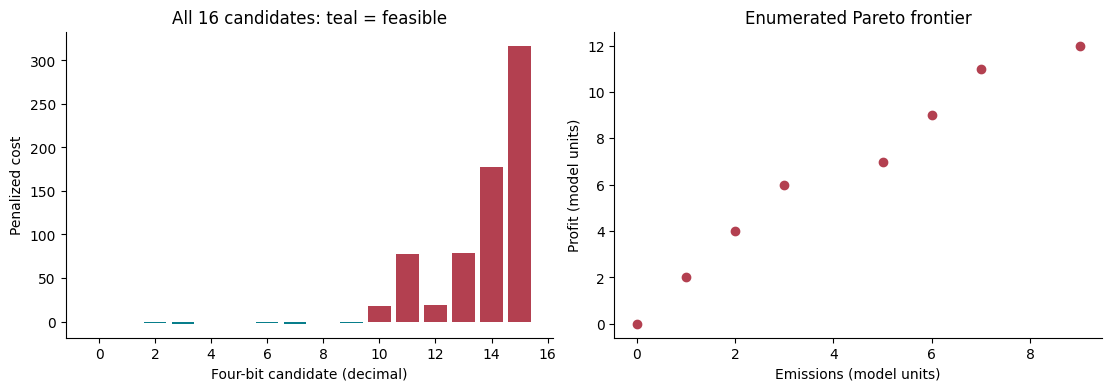

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
qaoa,4,59,1024,20261023


observable,estimate,standard_error,ideal_reference
qaoa,9.6199219,1.1031117,7.7465246


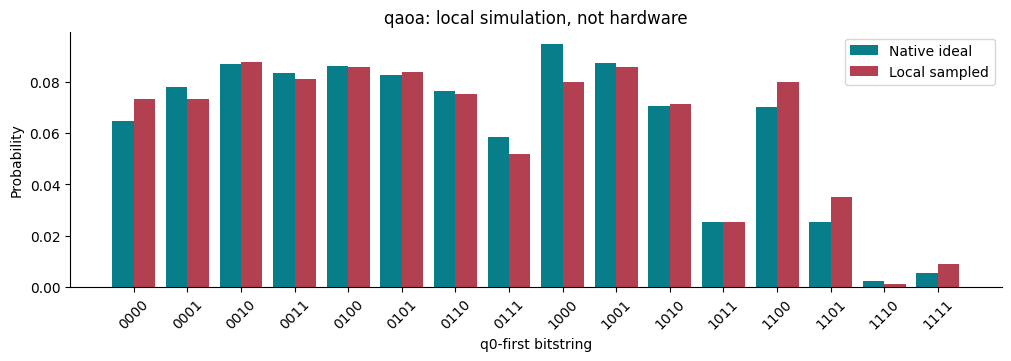

experiment,counts
qaoa,"{""0100"": 88, ""0111"": 53, ""1100"": 82, ""0011"": 83, ""0010"": 90, ""1010"": 73, ""1001"": 88, ""0110"": 77, ""0101"": 86, ""1101"": 36, ""0000"": 75, ""1000"": 82, ""0001"": 75, ""1011"": 26, ""1111"": 9, ""1110"": 1}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- qaoa ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
cx q[0],q[1];
cx q[1],q[2];
cx q[2],q[3];
rz(0.013656103933001415) q[3];
cx q[2],q[3];
cx q[1],q[2];
cx q[0],q[1];
cx q[0],q[1];
cx q[1],q[2];
rz(-0.20484155899502074) q[2];
cx q[1],q[2];
cx q[0],q[1];
cx q[0],q[1];
cx q[1],q[3];
rz(-0.095592727531009669) q[3];
cx q[1],q[3];
cx q[0],q[1];
cx q[0],q[1];
rz(0.3414025983250345) q[1];
cx q[0],q[1];
cx q[0],q[2];
cx q[2],q[3];
rz(-0.095592727531009669) q[3];
cx q[2],q[3];
cx q[0],q[2];
cx q[0],q[2];
rz(0.3414025983250345) q[2];
cx q[0],q[2];
cx q[0],q[3];
rz(0.17752935112901791) q[3];
cx q[0],q[3];
rz(-0.47577866102576805) q[0];
cx q[1],q[2];
cx q[2],q[3];
rz(-0.013656103933001415) q[3];
cx q[2],q[3];
cx q[1],q[2];
cx q[1],q[2];
rz(0.20484155899502074) q[2];
cx q[1],q[2];
cx q[1],q[3];
rz(0.095592727531009669) q[3];
cx q[1],q[3];
rz(-0.34031011001039441) q[1];
cx q[2],q[3];
rz(0.095592727531009669) q[3];
cx q[2],q[3];
rz(-0.33266269180791

## 8. 结果解释、复做与非目标

展示完整 Pareto 表和 λ=1.2 的最终决策，避免将经典枚举成果归功于量子采样。最优目标差只针对当前权重有效。

两变量有界整数模型；不包含通用混合整数、无限规模、多目标全部偏好或业务决策自动化。排放和利润是合成单位。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/industry/05_integer-multiobjective_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 05_integer-multiobjective_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [Qiskit Optimization 变量与约束](https://qiskit-community.github.io/qiskit-optimization/tutorials/01_quadratic_program.html)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。